In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from src.mass_detect.scripts.config import CENTRE_INDEX, PATCHES_DIR, QC_FIGURE_FILE
from src.mass_detect.scripts.patches import cut_lidc_patches, cut_lndb_patches
from src.mass_detect.scripts.qc import check_patch_coordinates, check_patch_files, make_patch_qc_figure
pd.set_option("display.width", 140)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    3D Patches Around Every Nodule
  </h1>
  <p>
    The model does not see a whole CT scan, only a small cube around each finding, and every radiomic feature is measured inside it. This notebook explains how the cube is cut, shows that it is cut in the right place and checks every patch of the 1219 LNDb training findings and of the LIDC IDRI nodules. The functions live in <strong>src/mass_detect/scripts/patches.py</strong> (cutting) and <strong>src/mass_detect/scripts/qc.py</strong> (checks).
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What a patch is
  </h3>
  <p>
    A patch is a cube of 64 mm around the centre of a finding, given in world coordinates (mm). It is resampled to 0.6 mm voxels, so the array has 107 x 107 x 107 voxels and the centre falls exactly on voxel (53, 53, 53). The values are raw Hounsfield units (int16). The array axes are (z, y, x) and they are aligned with the world axes, whatever the tilt of the CT, so every patch is oriented in the same way.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Why 3D?
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Size is best measured as a volume.</strong> Size is the strongest single predictor of malignancy, and the Fleischner Society gives its thresholds both as diameters and as volumes (MacMahon et al., 2017). A diameter measured on one slice depends on which slice is chosen.</li>
    <li style="margin-bottom: 8px;"><strong>Shape and texture are defined in 3D.</strong> Volume, sphericity, elongation and flatness only exist in three dimensions, and the IBSI defines its shape and texture features on volumes (Zwanenburg et al., 2020).</li>
    <li style="margin-bottom: 8px;"><strong>A single slice can mislead.</strong> A vessel cut across looks like a small round blob on an axial slice, exactly like a nodule; only along the third axis does it show itself as a tube.</li>
  </ul>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Why this voxel?
  </h3>
  <p>
    Texture features change when the voxel size changes (Shafiq-ul-Hassan et al., 2017), so every patch is resampled to the same isotropic voxel, which makes the features comparable between scans with different pixel sizes and slice spacings. The voxel is 0.6 mm in every direction, chosen with the sensitivity analysis at the end of notebook 05 (0.6, 1, 1.5 and 2 mm): 0.6 mm predicted best and kept every small nodule.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Why 64 mm?
  </h3>
  <p>
    A cube around the centre of the finding is the natural unit, and it is also what the LNDb authors distribute (the script getNoduleCubes.py cuts cubes of 51 mm); the foundation model of Pai et al. (2024) takes 50 mm cubes around the lesion centre. The cube must hold the whole region drawn by the radiologists, plus the tissue that the Laplacian of Gaussian filters need around it. Notebook 05 measures it: a 64 mm cube cuts no region of the cohort.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Patches for LIDC IDRI
  </h3>
  <p>
    LIDC IDRI scans are folders of DICOM slices, so they are read differently, but everything after reading the scan is shared with LNDb (the function extract_patch in patches.py): a LIDC IDRI patch and a LNDb patch are cut in exactly the same way, with 0.6 mm voxels, world axes and raw Hounsfield units.
  </p>
  <p>
    SimpleITK reads the DICOM series, sorts the slices along the scan axis and applies RescaleSlope and RescaleIntercept, so the voxels are already in Hounsfield units. The nodule table keeps the centre of every LIDC IDRI nodule as voxel indices (row, column, slice) taken from pylidc. SimpleITK turns these indices into world coordinates using the origin, spacing and direction of the scan, which also works for the few scans whose slices are not axis aligned.
  </p>
</div>

In [2]:
# Cut the patches if they are not on disk yet (src/mass_detect/scripts/patches.py):
# the LNDb training findings and the LIDC IDRI nodules
if not (PATCHES_DIR / "manifest_train.csv").exists():
    cut_lndb_patches("train")
if not (PATCHES_DIR / "manifest_lidc.csv").exists():
    cut_lidc_patches()

train = pd.read_csv(PATCHES_DIR / "manifest_train.csv")
lidc = pd.read_csv(PATCHES_DIR / "manifest_lidc.csv")
print("patches on disk:", {"LNDb train": len(train), "LIDC IDRI": len(lidc)})

patches on disk: {'LNDb train': 1219, 'LIDC IDRI': 2663}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Testing the cut with a known answer
  </h3>
  <p>
    Each test builds an artificial CT with a smooth bright blob at a known physical point, with different voxel sizes and tilts, cuts a patch around some centre and checks that the blob lands on the voxel where it must. A test only means something if it can fail, so we also broke the code on purpose in three ways (swapped axes, ignored tilt, a centre shifted by 3 mm) and each break was caught. The tests live in src/mass_detect/tests/test_patches.py.
  </p>
</div>

In [3]:
# The unit tests of the patches (src/mass_detect/tests/test_patches.py)
from src.mass_detect.tests import test_patches

tests = [getattr(test_patches, name) for name in dir(test_patches) if name.startswith("test_")]
for test in tests:
    test()
    print("passed:", test.__name__)

passed: test_axis_order_is_z_y_x


passed: test_blob_at_the_centre_lands_on_the_centre_voxel_with_anisotropic_spacing


passed: test_naive_conversion_would_fail_on_a_tilted_ct


passed: test_nearest_neighbour_keeps_integer_labels
passed: test_points_outside_the_ct_are_filled_with_air_and_counted


passed: test_tilted_direction_is_handled


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Does it work on real scans?
  </h3>
  <p>
    For readings that come with a segmentation mask, the centre we cut around should fall on the centre of the mask. We cut a patch of the mask and measure how far its centre of mass is from the centre voxel, in millimetres. We used 12 scans, 6 tilted and 6 not tilted. If axes were swapped or the tilt ignored, the distance would be tens of millimetres.
  </p>
</div>

In [4]:
check_patch_coordinates()

45 readings with a mask, from 12 CTs (tilt of the chosen CTs: {'not tilted': {'min': 0.0, 'max': 0.0}, 'tilted': {'min': 3.3, 'max': 6.7}})
readings whose mask is empty inside the patch: 0

distance between the mask centroid and the centre voxel (mm):
            median  90th percentile   max
group                                    
not tilted    0.46             0.60  0.63
tilted        0.44             0.61  0.91
share below 1 mm: 100.0%
share below 2 mm: 100.0%
share below 5 mm: 100.0%

largest distances:
     group  ct  tilt  distance_mm  voxels
    tilted 121  3.90         0.91      65
    tilted 244  6.68         0.65      82
not tilted 162  0.00         0.63     496
    tilted 121  3.90         0.62     248
not tilted 290  0.00         0.61     196


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Every distance is below 1 mm: the median is 0.46 mm in the untilted scans and 0.44 mm in the tilted ones, and the largest is 0.91 mm, less than two voxels of 0.6 mm. Tilted and untilted scans behave the same. What this does not cover: the tilted scans we picked go up to about 7 degrees, while the data reach 13. That extreme is covered by the artificial tests above.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The full run
  </h3>
  <p>
    All findings were cut one scan at a time, to keep the memory low. Each finding gets a row in a manifest with its status, where its centre falls inside the scan, and how much of its patch lies outside it.
  </p>
</div>

In [5]:
# One summary row per manifest
rows = []
for name, manifest in (("LNDb train", train), ("LIDC IDRI", lidc)):
    ok = manifest[manifest["status"] == "ok"]
    rows.append({
        "patches": name,
        "rows": len(manifest),
        "ok": len(ok),
        "centre outside the scan": int((manifest["status"] == "centre_outside_volume").sum()),
        "more than 5% outside": int((ok["outside_fraction"] > 0.05).sum()),
        "more than 50% outside": int((ok["outside_fraction"] > 0.5).sum()),
    })
pd.DataFrame(rows).set_index("patches")

,rows,ok,centre outside the scan,more than 5% outside,more than 50% outside
patches,,,,,
LNDb train,1219,1219,0,25,0
LIDC IDRI,2663,2663,0,44,0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Checking every patch
  </h3>
  <p>
    A patch can look fine and still be wrong: a mask saved in place of the CT, a patch cut with an old geometry, or intensities that were never converted to Hounsfield units. Instead of looking at a few patches, every patch goes through the same checklist (check_patch_files in qc.py):
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">it is stored as int16;</li>
    <li style="margin-bottom: 8px;">it has the size of the configured cube (107 voxels per side);</li>
    <li style="margin-bottom: 8px;">it has enough distinct values to be a CT and not a mask;</li>
    <li style="margin-bottom: 8px;">it contains lung air (HU of minus 700 or less) and tissue (HU of 0 or more), as every patch of a lung must;</li>
    <li style="margin-bottom: 8px;">most of it lies inside the scan.</li>
  </ol>
  <p>
    We confirmed that the checklist catches what it is meant to catch: a mask saved as a patch fails three checks, and a patch with the old geometry fails the size check.
  </p>
</div>

In [6]:
# Run the checklist on every patch (src/mass_detect/scripts/qc.py)
checks = pd.concat({"LNDb train": check_patch_files(train), "LIDC IDRI": check_patch_files(lidc)})

# For each check, the number of patches that fail it
failed = ~checks.drop(columns="patch_id")
failed.groupby(level=0).sum().T

,LIDC IDRI,LNDb train
stored as int16,0,0
shape of the configured cube,0,0
"looks like a CT, not a mask",0,0
contains lung air (HU of -700 or less),0,0
contains tissue (HU of 0 or more),0,0
mostly inside the scan,0,0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    No patch fails the checklist: every one is stored as int16, has the size of the configured cube, looks like a CT and not a mask, contains lung air and tissue, and lies mostly inside the scan. The air check needed a closer look. With a first threshold of minus 900 HU, 31 LIDC IDRI patches from 20 scans failed, although they are full of lung. Their lowest value lies between minus 820 and minus 899 HU and their highest is bone (about 1000 HU), so the values are in Hounsfield units and the conversion worked; the lung in these scans simply reads a little denser, as happens with noise, partial volume or a different calibration of the scanner. The threshold was therefore set to minus 700 HU, which still catches any patch whose values were never converted, since those start at 0. This small difference between LIDC IDRI scanners is one more part of the scanner effect that notebook 06 has to deal with.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   A visual check
  </h3>
  <p>
    Twelve random patches, six from LNDb and six from LIDC IDRI, with the three central views and the centre marked in red. The lung window (level minus 600 HU, width 1500 HU) is used only to display them; the patches keep their raw values.
  </p>
</div>

saved /home/anasofia/labiacd/mass_detect/reports/figures/patch_qc.png


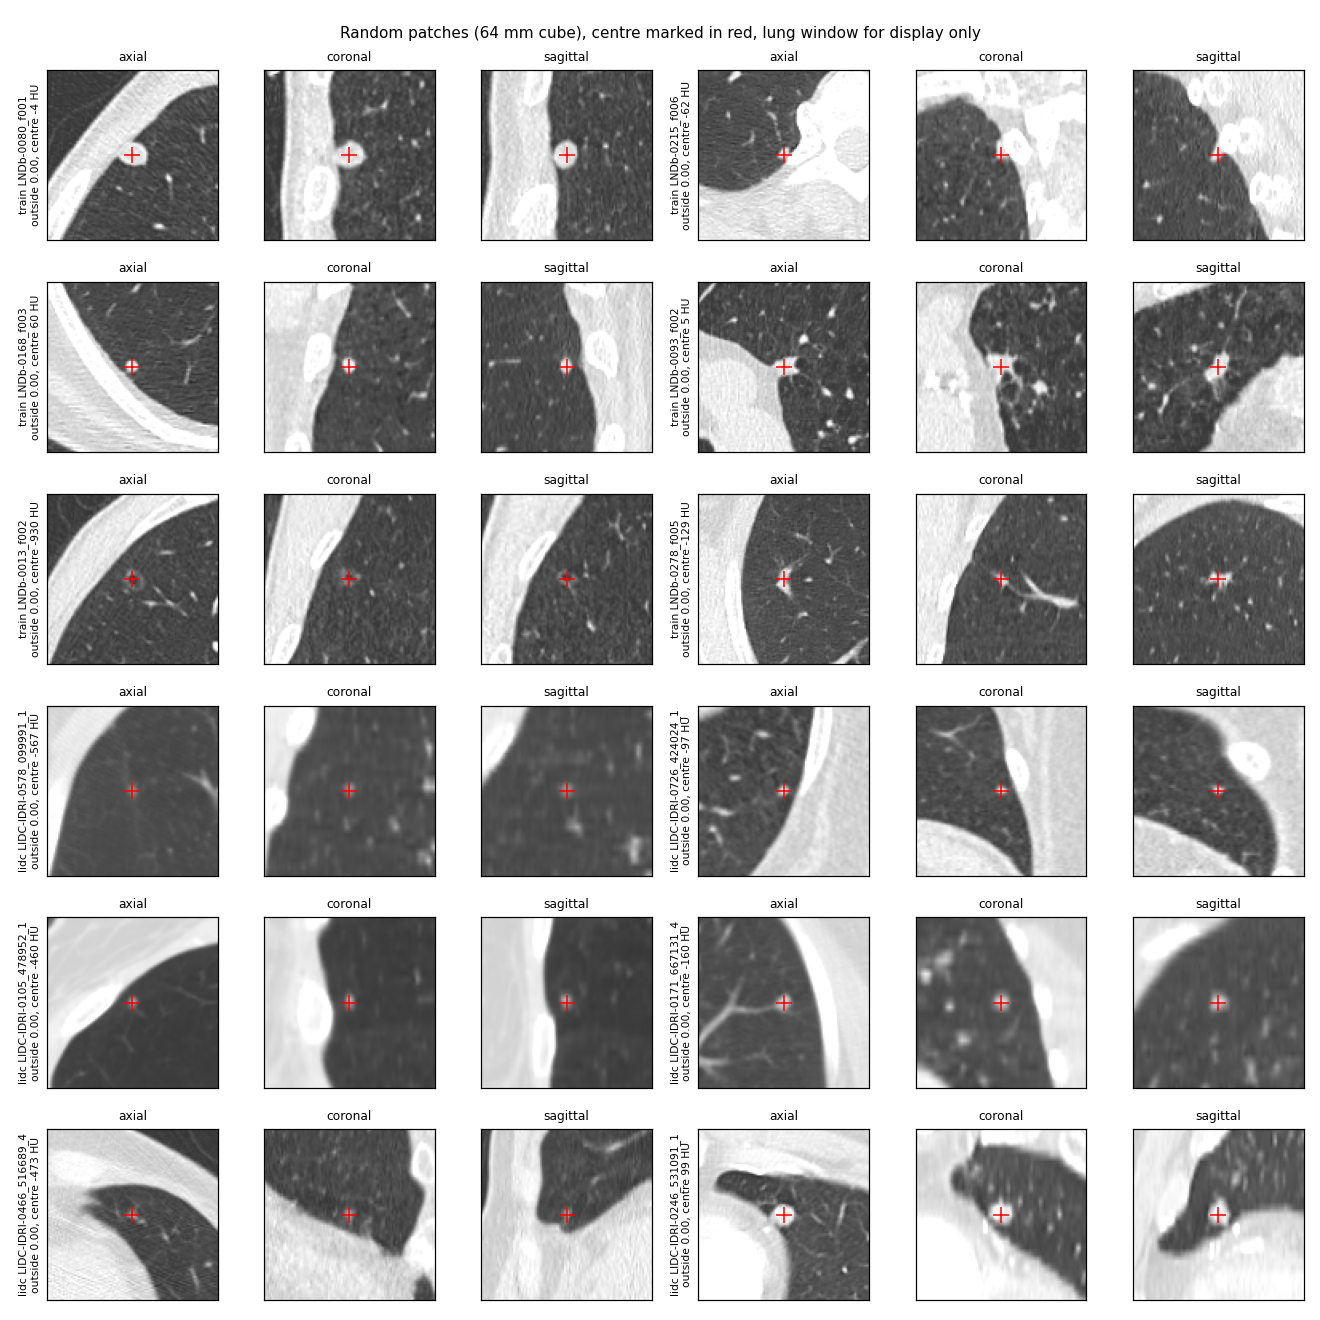

In [7]:
make_patch_qc_figure()
plt.close("all")            # the figure is shown from the saved file below
Image(filename=str(QC_FIGURE_FILE))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Is every LIDC IDRI patch on its nodule?
  </h3>
  <p>
    Before using a LIDC IDRI patch we make sure it is centred on the right nodule. The centre is computed in two independent ways: from the DICOM header of the first slice, and by letting SimpleITK convert the nodule's voxel position into millimetres with the geometry of the scan. If both give the same point, the patch is in the right place.
  </p>
</div>

In [8]:
check = lidc["coord_check_mm"]          # distance between the two computations of the centre
verified = lidc["position_verified"]
print(f"{len(lidc)} LIDC nodules, status: {lidc['status'].value_counts().to_dict()}")
print(f"distance between the two computations: median {check.median():.3f} mm, 99th percentile {check.quantile(0.99):.3f} mm")
print(f"position verified: {verified.sum()} | not verified: {(~verified).sum()}")
print(f"    tilted series without a header point: {check.isna().sum()}")
print(f"    disagreement above 1 mm: {(check > 1).sum()}")

2663 LIDC nodules, status: {'ok': 2663}
distance between the two computations: median 0.000 mm, 99th percentile 0.000 mm
position verified: 2621 | not verified: 42
    tilted series without a header point: 36
    disagreement above 1 mm: 6


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    For 2619 nodules the two points agree to less than a micrometre, and for two more within 0.52 mm. Six nodules in five series disagree by more than 1 mm, because pylidc and SimpleITK order the slices differently in those series, so the same slice number points to different slices. Another 36 nodules are in tilted series, where the header method does not apply, so their position cannot be confirmed. We leave these 42 nodules (1.6%) out: losing a few examples costs little, while a patch centred on the wrong tissue would give the model the features of something that is not the nodule. As a visual check, the figure below shows six random verified patches with a red cross at the centre, which should sit on the nodule.
  </p>
</div>

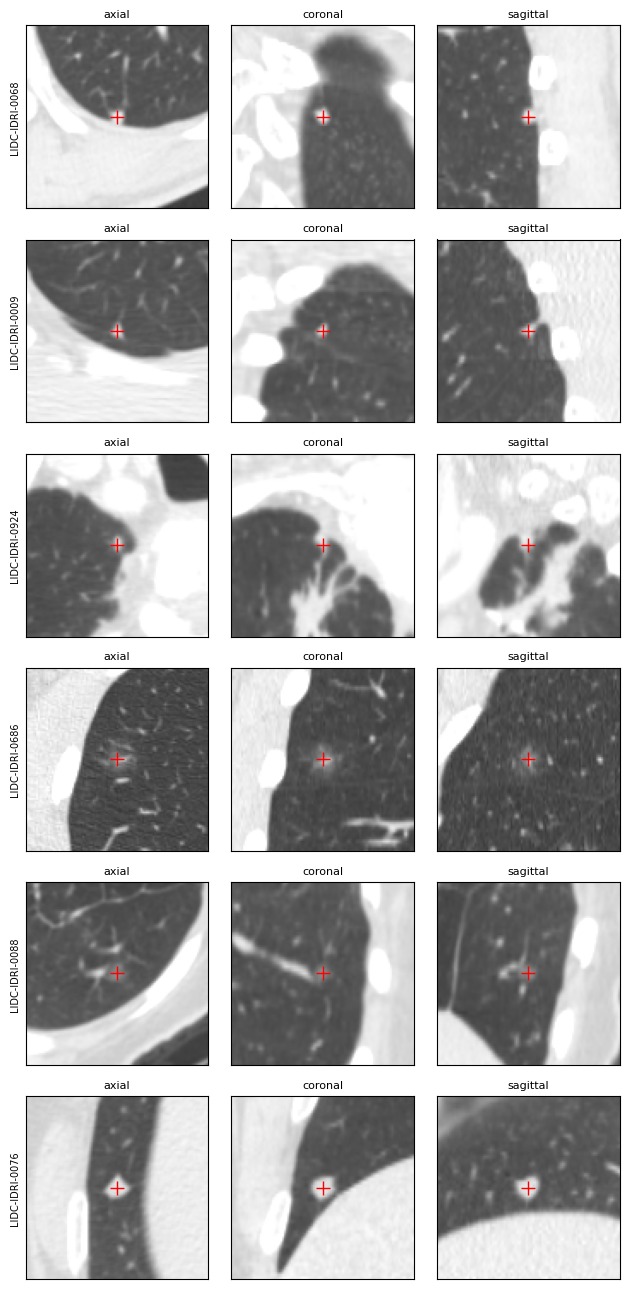

LIDC verified nodules: median HU at the centre -84, share above minus 300 HU 0.73


In [9]:
def centre_hu(files): # Mean HU of the 3 x 3 x 3 voxels around the centre of each patch
    middle = slice(CENTRE_INDEX - 1, CENTRE_INDEX + 2)
    values = []
    for file in files:
        patch = np.load(PATCHES_DIR / file, mmap_mode="r")
        values.append(patch[middle, middle, middle].mean())
    return np.array(values)

# Six random verified LIDC IDRI patches: the three central views, with the centre marked in red
verified = lidc[lidc["position_verified"]]
rng = np.random.default_rng(0)
picks = verified.iloc[rng.choice(len(verified), 6, replace=False)]

fig, axes = plt.subplots(6, 3, figsize=(6.5, 13))
for row_axes, item in zip(axes, picks.itertuples()):
    patch = np.load(PATCHES_DIR / item.file)
    views = {"axial": patch[CENTRE_INDEX], "coronal": patch[:, CENTRE_INDEX, :], "sagittal": patch[:, :, CENTRE_INDEX]}
    for axis, (name, view) in zip(row_axes, views.items()):
        origin = "upper" if name == "axial" else "lower"      # head up in the coronal and sagittal views
        axis.imshow(view, cmap="gray", vmin=-1350, vmax=150, origin=origin)
        axis.plot(CENTRE_INDEX, CENTRE_INDEX, "r+", markersize=10)
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_title(name, fontsize=8)
    row_axes[0].set_ylabel(item.patch_id[:14], fontsize=7)
plt.tight_layout()
plt.show()

hu = centre_hu(verified["file"])
print(f"LIDC verified nodules: median HU at the centre {np.median(hu):.0f}, share above minus 300 HU {(hu > -300).mean():.2f}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The cube is 64 mm. Notebook 05 checks that no region drawn by the radiologists is cut.</li>
    <li style="margin-bottom: 8px;">25 LNDb and 44 LIDC IDRI patches have more than 5% of their voxels outside the scan, near the edge of the volume, and none more than 50%. They are kept: the voxels outside are filled with air, and the features are computed inside the radiologists' region.</li>
    <li style="margin-bottom: 8px;">42 LIDC IDRI nodules (1.6%) whose position could not be confirmed are not used.</li>
    <li style="margin-bottom: 8px;">In some LIDC IDRI scans the lung reads slightly denser than in the others, part of the scanner effect between and within the datasets.</li>
  </ul>
</div>